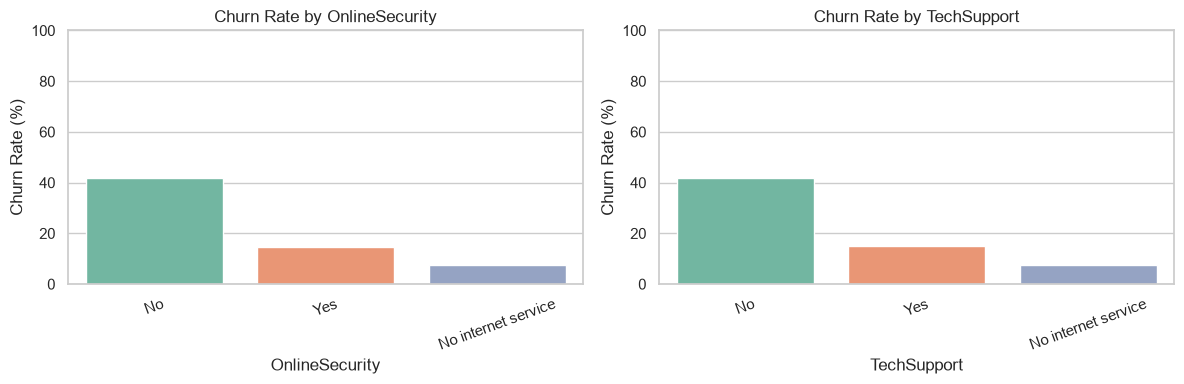

In [10]:
# Churn rate by service availability
service_features = ["OnlineSecurity", "TechSupport"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for axis, feature in zip(axes, service_features):
    churn_rate = (
        pd.crosstab(df[feature], df["Churn"], normalize="index")["Yes"]
        .mul(100)
        .sort_values(ascending=False)
    )

    sns.barplot(
        x=churn_rate.index,
        y=churn_rate.values,
        hue=churn_rate.index,
        palette="Set2",
        legend=False,
        ax=axis
    )

    axis.set_title(f"Churn Rate by {feature}")
    axis.set_xlabel(feature)
    axis.set_ylabel("Churn Rate (%)")
    axis.set_ylim(0, 100)
    axis.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

### Finding

Customers without Online Security or Tech Support have churn rates of approximately 42%. Customers with these services have much lower churn rates of approximately 14–15%. These services are strongly associated with customer retention, but the analysis does not establish causation.

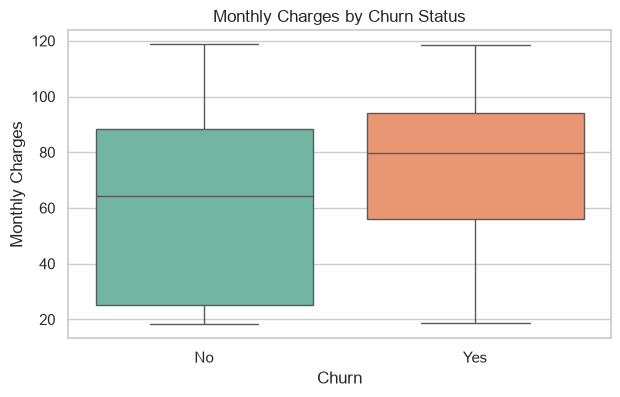

,customer_count,mean,median
Churn,,,
No,5174,61.27,64.43
Yes,1869,74.44,79.65


In [9]:
# Monthly charges by churn status
plt.figure(figsize=(7, 4))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges",
    hue="Churn",
    palette="Set2",
    legend=False
)

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.show()

df.groupby("Churn")["MonthlyCharges"].agg(
    customer_count="count",
    mean="mean",
    median="median"
).round(2)

### Finding

Customers who churned had higher monthly charges than customers who stayed. The median monthly charge was 79.65 for churned customers and 64.43 for retained customers. Monthly charges may be an important predictive feature.

,churn_rate_percent
TenureGroup,
0-6 months,52.9
7-12 months,35.9
13-24 months,28.7
25-48 months,20.4
49+ months,9.5


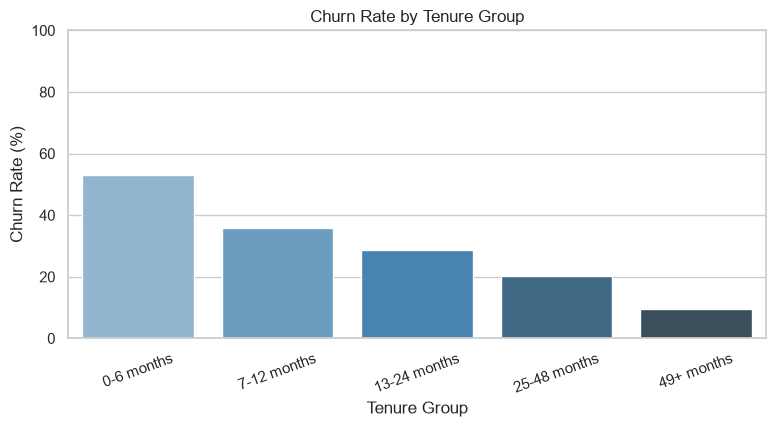

In [7]:
# Churn rate by tenure group
tenure_bins = [-1, 6, 12, 24, 48, float("inf")]
tenure_labels = ["0-6 months", "7-12 months", "13-24 months", "25-48 months", "49+ months"]

df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=tenure_bins,
    labels=tenure_labels
)

tenure_churn_rate = (
    pd.crosstab(df["TenureGroup"], df["Churn"], normalize="index")["Yes"]
    .mul(100)
)

display(tenure_churn_rate.to_frame("churn_rate_percent").round(1))

plt.figure(figsize=(9, 4))
sns.barplot(
    x=tenure_churn_rate.index,
    y=tenure_churn_rate.values,
    hue=tenure_churn_rate.index,
    palette="Blues_d",
    legend=False
)

plt.title("Churn Rate by Tenure Group")
plt.xlabel("Tenure Group")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 100)
plt.xticks(rotation=20)
plt.show()

### Finding

Churn decreases as customer tenure increases. Customers in their first six months have the highest churn rate (52.9%), while customers with 49 or more months of tenure have the lowest rate (9.5%). Early customer retention appears to be a key business opportunity.

,churn_rate_percent
Contract,
Month-to-month,42.7
One year,11.3
Two year,2.8


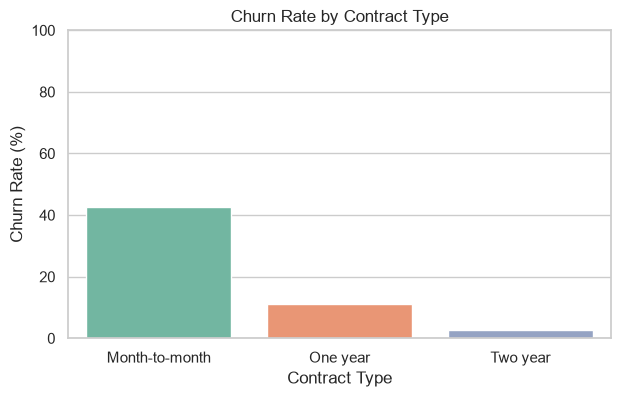

In [6]:
# Churn rate by contract type
contract_churn_rate = (
    pd.crosstab(df["Contract"], df["Churn"], normalize="index")["Yes"]
    .mul(100)
    .sort_values(ascending=False)
)

display(contract_churn_rate.to_frame("churn_rate_percent").round(1))

plt.figure(figsize=(7, 4))
sns.barplot(
    x=contract_churn_rate.index,
    y=contract_churn_rate.values,
    hue=contract_churn_rate.index,
    palette="Set2",
    legend=False
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 100)
plt.show()

### Finding

Customers with month-to-month contracts have the highest churn rate (42.7%). Churn decreases substantially for one-year and two-year contracts, making contract type a potentially important predictive feature.

,customers,percentage
Churn,,
No,5174,73.5
Yes,1869,26.5


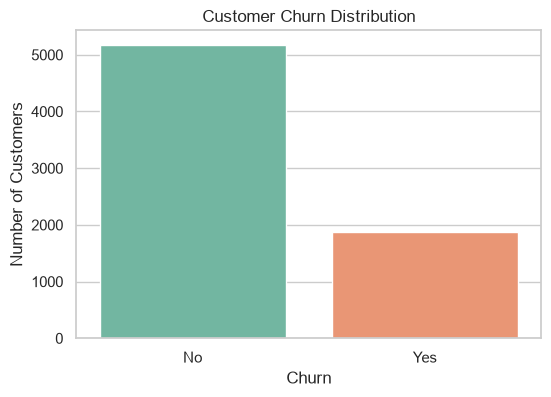

In [5]:
# Churn distribution
churn_counts = df["Churn"].value_counts()
churn_rates = df["Churn"].value_counts(normalize=True).mul(100).round(1)

display(pd.DataFrame({
    "customers": churn_counts,
    "percentage": churn_rates
}))

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Churn", hue="Churn", palette="Set2", legend=False)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

### Finding

26.5% of customers churned. The target class is moderately imbalanced, so model evaluation should focus on Recall, F1 score, and PR-AUC rather than accuracy alone.

In [4]:
# Convert TotalCharges to numeric and inspect missing values
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Missing values in TotalCharges:", df["TotalCharges"].isna().sum())

df.loc[df["TotalCharges"].isna(), [
    "customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"
]]

Missing values in TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


In [3]:
# Data types and data quality check
print("Duplicate rows:", df.duplicated().sum())
print()

quality_report = pd.DataFrame({
    "data_type": df.dtypes.astype(str),
    "missing_values": df.isna().sum(),
    "empty_strings": df.apply(
        lambda column: column.astype("string").str.strip().eq("").sum()
    )
})

quality_report

Duplicate rows: 0



,data_type,missing_values,empty_strings
customerID,object,0,0
gender,object,0,0
SeniorCitizen,int64,0,0
Partner,object,0,0
Dependents,object,0,0
tenure,int64,0,0
PhoneService,object,0,0
MultipleLines,object,0,0
InternetService,object,0,0
OnlineSecurity,object,0,0


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv("../data/raw/Telco-Customer-Churn.csv")

print(f"Dataset size: {df.shape[0]} rows × {df.shape[1]} columns")
df.head()

Dataset size: 7043 rows × 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
